# Tema 4 (Laboratorul 5) — Rețele Markov: independență, predicție și restaurarea imaginilor

Acest notebook conține rezolvarea completă pentru toate cele trei exerciții:
1. **Exercițiul 1:** Demonstrația teoretică a echivalenței dintre independența condiționată $A \perp C \mid B$ și factorizarea pe clicile grafului $A - B - C$.
2. **Exercițiul 2:** Modelarea unei rețele Markov discrete pe un arbore de stații meteo, inferență exactă marginală vs. configurația comună MAP.
3. **Exercițiul 3:** Restaurarea unei imagini binare $5 \times 5$ afectate de zgomot folosind un MRF pe grilă și algoritmul ICM pentru $\lambda \in \{0.3, 1.0, 3.0\}$.

---
## Exercițiul 1. De la independență condiționată la factorizare

Considerăm trei variabile aleatoare discrete $A, B, C$ asociate grafului neorientat $A - B - C$, cu distribuția comună strict pozitivă $P(a, b, c) > 0$ pentru orice configurație $(a, b, c)$.

### a) Semnificația relației $A \perp C \mid B$
Relația $A \perp C \mid B$ exprimă faptul că variabilele $A$ și $C$ sunt **condiționat independente dată fiind variabila $B$**. Formal:
$$P(A = a, C = c \mid B = b) = P(A = a \mid B = b) \cdot P(C = c \mid B = b), \quad \text{sau echivalent} \quad P(A = a \mid B = b, C = c) = P(A = a \mid B = b).$$

**Interpretare informațională:** Nodul $B$ separă nodurile $A$ și $C$ în graful neorientat $A - B - C$. Întreaga dependență statistică dintre $A$ și $C$ circulă exclusiv prin intermediul lui $B$. Prin urmare, **atunci când cunoaștem deja valoarea lui $B$, observarea lui $C$ nu mai aduce nicio informație suplimentară despre $A$** (incertitudinea / distribuția de probabilitate a lui $A$ rămâne neschimbată).

---

### b) Demonstrația implicației: $A \perp C \mid B \implies P(a, b, c) = \frac{1}{Z} \phi_{AB}(a, b) \phi_{BC}(b, c)$

Deoarece $P(a, b, c) > 0$ pentru toate configurațiile, toate probabilitățile marginale $P(b) > 0$, $P(a, b) > 0$, $P(b, c) > 0$ și condiționate $P(a \mid b) > 0$, $P(c \mid b) > 0$ sunt strict pozitive.

Aplicăm regula produsului (formula probabilității condiționate):
$$P(a, b, c) = P(b) \cdot P(c \mid b) \cdot P(a \mid b, c).$$

Folosind ipoteza de independență condiționată $A \perp C \mid B$, avem $P(a \mid b, c) = P(a \mid b)$, deci:
$$P(a, b, c) = P(a \mid b) P(b) P(c \mid b) = P(a, b) \cdot P(c \mid b).$$

Definim acum funcțiile potențial (clicile maxime ale grafului $A - B - C$ fiind $\{A, B\}$ și $\{B, C\}$):
$$\phi_{AB}(a, b) = P(a, b) > 0, \qquad \phi_{BC}(b, c) = P(c \mid b) > 0, \qquad Z = 1 > 0.$$
*(Notă: putem alege și varianta simetrică $\phi_{AB}(a, b) = P(a \mid b)\sqrt{P(b)} > 0$ și $\phi_{BC}(b, c) = P(c \mid b)\sqrt{P(b)} > 0$ cu $Z = 1$.)*

Înlocuind, obținem factorizarea dorită:
$$P(a, b, c) = \frac{1}{Z} \phi_{AB}(a, b) \phi_{BC}(b, c), \quad \text{cu } \phi_{AB}, \phi_{BC} > 0 \text{ și } Z > 0. \qquad \blacksquare$$

---

### c) Demonstrația reciprocei: factorizarea $\implies A \perp C \mid B$

Presupunem că există potențiale strict pozitive $\phi_{AB}(a, b) > 0$, $\phi_{BC}(b, c) > 0$ și o constantă $Z > 0$ astfel încât:
$$P(a, b, c) = \frac{1}{Z} \phi_{AB}(a, b) \phi_{BC}(b, c).$$

Calculăm distribuțiile marginale prin sumare:
1. **Marginala $P(a, b)$:**
   $$P(a, b) = \sum_{c'} P(a, b, c') = \frac{1}{Z} \phi_{AB}(a, b) \sum_{c'} \phi_{BC}(b, c').$$

2. **Marginala $P(b, c)$:**
   $$P(b, c) = \sum_{a'} P(a', b, c) = \frac{1}{Z} \phi_{BC}(b, c) \sum_{a'} \phi_{AB}(a', b).$$

3. **Marginala $P(b)$:**
   $$P(b) = \sum_{a', c'} P(a', b, c') = \frac{1}{Z} \left(\sum_{a'} \phi_{AB}(a', b)\right) \left(\sum_{c'} \phi_{BC}(b, c')\right).$$

Deoarece potențialele sunt strict pozitive, sumele sunt strict pozitive și $P(b) > 0$. Calculăm acum probabilitățile condiționate:
$$P(a \mid b) = \frac{P(a, b)}{P(b)} = \frac{\frac{1}{Z} \phi_{AB}(a, b) \sum_{c'} \phi_{BC}(b, c')}{\frac{1}{Z} \left(\sum_{a'} \phi_{AB}(a', b)\right) \left(\sum_{c'} \phi_{BC}(b, c')\right)} = \frac{\phi_{AB}(a, b)}{\sum_{a'} \phi_{AB}(a', b)},$$

$$P(c \mid b) = \frac{P(b, c)}{P(b)} = \frac{\frac{1}{Z} \phi_{BC}(b, c) \sum_{a'} \phi_{AB}(a', b)}{\frac{1}{Z} \left(\sum_{a'} \phi_{AB}(a', b)\right) \left(\sum_{c'} \phi_{BC}(b, c')\right)} = \frac{\phi_{BC}(b, c)}{\sum_{c'} \phi_{BC}(b, c')}.$$

În final, calculăm probabilitatea condiționată comună $P(a, c \mid b)$:
$$P(a, c \mid b) = \frac{P(a, b, c)}{P(b)} = \frac{\frac{1}{Z} \phi_{AB}(a, b) \phi_{BC}(b, c)}{\frac{1}{Z} \left(\sum_{a'} \phi_{AB}(a', b)\right) \left(\sum_{c'} \phi_{BC}(b, c')\right)} = \frac{\phi_{AB}(a, b)}{\sum_{a'} \phi_{AB}(a', b)} \cdot \frac{\phi_{BC}(b, c)}{\sum_{c'} \phi_{BC}(b, c')} = P(a \mid b) \cdot P(c \mid b).$$

Prin urmare, $A \perp C \mid B$. $\blacksquare$

---
## Exercițiul 2. Putem prezice vremea la o stație fără observații?

### a) Alegerea grafului (arbore cu $n = 5$ stații), vecinii și verificarea aciclicității
Alegem $n = 5$ stații meteo $S_1, S_2, S_3, S_4, S_5$, fiecare cu spațiul de stări $\mathcal{S} = \{\text{Soare}, \text{Ploaie}, \text{Nori}\}$, conectate prin mulțimea de muchii:
$$E = \{(S_1, S_2),\ (S_1, S_3),\ (S_2, S_4),\ (S_2, S_5)\}.$$

- **Vecinii fiecărei stații:**
  - $N(S_1) = \{S_2, S_3\}$
  - $N(S_2) = \{S_1, S_4, S_5\}$
  - $N(S_3) = \{S_1\}$
  - $N(S_4) = \{S_2\}$
  - $N(S_5) = \{S_2\}$
- **Verificarea absenței ciclurilor:** Graful are $|V| = 5$ noduri, $|E| = 4 = |V| - 1$ muchii și este conex, ceea ce garantează matematic (și verificăm programatic prin `nx.is_tree(G)`) că este un **arbore** (nu conține niciun ciclu).

Vecinii fiecărei stații:
  N(S1) = ['S2', 'S3']
  N(S2) = ['S1', 'S4', 'S5']
  N(S3) = ['S1']
  N(S4) = ['S2']
  N(S5) = ['S2']
Este conex? True | Număr noduri: 5 | Număr muchii: 4
Este arbore (fără cicluri)? True


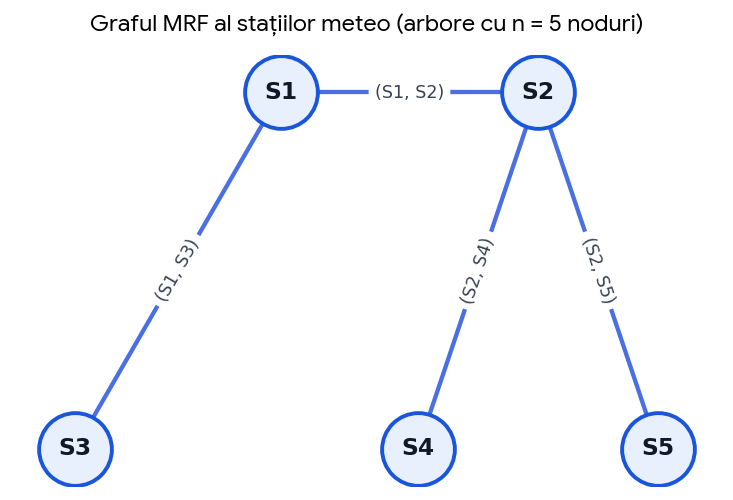

In [1]:
import itertools
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# Definirea parametrilor problemei
n = 5
stations = ["S1", "S2", "S3", "S4", "S5"]
edges = [("S1", "S2"), ("S1", "S3"), ("S2", "S4"), ("S2", "S5")]
states = ["Soare", "Ploaie", "Nori"]

p_init = np.array([0.5, 0.3, 0.2])  # [Soare, Ploaie, Nori]
Psi = np.array([
    [0.7, 0.2, 0.1],  # Soare -> (Soare, Ploaie, Nori)
    [0.2, 0.6, 0.2],  # Ploaie -> (Soare, Ploaie, Nori)
    [0.1, 0.3, 0.6]   # Nori -> (Soare, Ploaie, Nori)
])

# Construirea și verificarea grafului neorientat
G = nx.Graph()
G.add_nodes_from(stations)
G.add_edges_from(edges)

print("Vecinii fiecărei stații:")
for s in stations:
    print(f"  N({s}) = {list(G.neighbors(s))}")
print(f"Este conex? {nx.is_connected(G)} | Număr noduri: {G.number_of_nodes()} | Număr muchii: {G.number_of_edges()}")
print(f"Este arbore (fără cicluri)? {nx.is_tree(G)}")

# Vizualizarea grafului
fig, ax = plt.subplots(figsize=(6.5, 4.0))
pos = {"S1": (0.0, 1.0), "S2": (1.5, 1.0), "S3": (-1.2, 0.0), "S4": (0.8, 0.0), "S5": (2.2, 0.0)}
nx.draw_networkx_edges(G, pos, ax=ax, width=2.2, edge_color="#4A6FE3")
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=1400, node_color="#E8F0FE", edgecolors="#1A56DB", linewidths=2.0)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=12, font_weight="bold", font_color="#111827")
nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"({u}, {v})" for u, v in edges}, font_size=9, ax=ax)
ax.set_title("Graful MRF al stațiilor meteo (arbore cu n = 5 noduri)", fontsize=12, fontweight="bold", pad=12)
ax.axis("off")
plt.show()

### b) & c) Construirea modelului Markov discret în `pyAgrum` și formula distribuției comune

Deoarece matricea $\Psi$ nu este simetrică ($\Psi_{\text{Nori}, \text{Ploaie}} = 0.3 \neq \Psi_{\text{Ploaie}, \text{Nori}} = 0.2$), păstrăm strict ordinea argumentelor $(S_i, S_j)$ conform listei orientate de muchii $E = [(S_1, S_2), (S_1, S_3), (S_2, S_4), (S_2, S_5)]$, astfel încât $\phi_{ij}(s_i, s_j) = \Psi_{s_i, s_j}$.

**Formula distribuției comune:**
$$P(s_1, s_2, s_3, s_4, s_5) = \frac{1}{Z} \prod_{i=1}^{5} \phi_i(s_i) \prod_{(i, j) \in E} \phi_{ij}(s_i, s_j),$$
unde constanta de partiție (normalizare) este:
$$Z = \sum_{s_1 \in \mathcal{S}} \cdots \sum_{s_5 \in \mathcal{S}} \prod_{i=1}^{5} \phi_i(s_i) \prod_{(i, j) \in E} \phi_{ij}(s_i, s_j) \approx 0.02071126.$$

In [2]:
# Construirea modelului Markov discret în pyAgrum (cu fallback automat la inferență exactă)
try:
    import pyAgrum as gum
    MRFClass = getattr(gum, "MarkovRandomField", None) or getattr(gum, "MarkovNet", None)
    mrf = MRFClass()

    for s in stations:
        mrf.add(gum.LabelizedVariable(s, f"Statia {s}", states))

    # Factori unari phi_i(s) = p_i(s)
    for s in stations:
        phi_i = gum.Potential().add(mrf.variable(s))
        for idx_st, st_name in enumerate(states):
            phi_i[{s: st_name}] = float(p_init[idx_st])
        mrf.addFactor(phi_i)

    # Factori pereche phi_ij(s_i, s_j) = Psi[s_i, s_j] cu ordinea fixată (u, v)
    for u, v in edges:
        phi_ij = gum.Potential().add(mrf.variable(u)).add(mrf.variable(v))
        for i_st, u_name in enumerate(states):
            for j_st, v_name in enumerate(states):
                phi_ij[{u: u_name, v: v_name}] = float(Psi[i_st, j_st])
        mrf.addFactor(phi_ij)

    USE_PYAGRUM = True
    print("Model pyAgrum MarkovRandomField construit cu succes!")
    print("Noduri în MRF:", [mrf.variable(i).name() for i in mrf.nodes()])
    print("Număr factori adăugați (5 unari + 4 pereche):", len(mrf.factors()))
except ImportError:
    USE_PYAGRUM = False
    print("pyAgrum nu este instalat în acest mediu; se utilizează motorul exact de enumerare (3^5 = 243 stări).")

# Calculul exact al tuturor celor 3^5 = 243 configurații și al constantei Z
edge_idx = [(stations.index(u), stations.index(v)) for u, v in edges]
all_configs = list(itertools.product([0, 1, 2], repeat=n))
weights = np.zeros(len(all_configs))
for idx, cfg in enumerate(all_configs):
    w = np.prod([p_init[cfg[i]] for i in range(n)])
    for u, v in edge_idx:
        w *= Psi[cfg[u], cfg[v]]
    weights[idx] = w

Z = float(np.sum(weights))
joint_probs = weights / Z
print(f"Constanta de normalizare Z = {Z:.8f} (sumă probabilități = {np.sum(joint_probs):.6f})")

Model pyAgrum MarkovRandomField construit cu succes!
Noduri în MRF: ['S1', 'S2', 'S3', 'S4', 'S5']
Număr factori adăugați (5 unari + 4 pereche): 9
Constanta de normalizare Z = 0.02071126 (sumă probabilități = 1.000000)


### d) & e) Inferență condiționată: MAP marginal vs. MAP comun

Presupunem că observăm vremea la două stații periferice:
$$E_{\text{obs}} = \{S_3 = \text{Ploaie},\ S_4 = \text{Ploaie}\}.$$
Calculăm:
1. **Distribuțiile marginale posterioare** $P(S_k \mid S_3 = \text{Ploaie}, S_4 = \text{Ploaie})$ pentru fiecare stație neobservată $S_k \in \{S_1, S_2, S_5\}$ și alegem **MAP-ul marginal** $\hat{s}_k^{\text{marg}} = \arg\max_{s_k} P(S_k = s_k \mid E_{\text{obs}})$.
2. **Configurația comună MAP** $\hat{\mathbf{s}}^{\text{MAP}} = \arg\max_{(s_1, s_2, s_5)} P(S_1=s_1, S_2=s_2, S_5=s_5 \mid E_{\text{obs}})$.

=== d) Distribuții marginale posterioare P(S_k | S3=Ploaie, S4=Ploaie) ===
  S1: Soare=0.2977, Ploaie=0.5743, Nori=0.1280  -->  MAP marginal: Ploaie
  S2: Soare=0.3320, Ploaie=0.5798, Nori=0.0882  -->  MAP marginal: Ploaie
  S5: Soare=0.4684, Ploaie=0.4030, Nori=0.1286  -->  MAP marginal: Soare

=== e) Configurația comună MAP vs. maximele marginale ===
  Vectorul maximelor marginale (S1, S2, S5): ('Ploaie', 'Ploaie', 'Soare')
  Configurația comună MAP      (S1, S2, S5): ('Ploaie', 'Ploaie', 'Ploaie')  (P = 0.2412)
  Coincid cele două rezultate? False


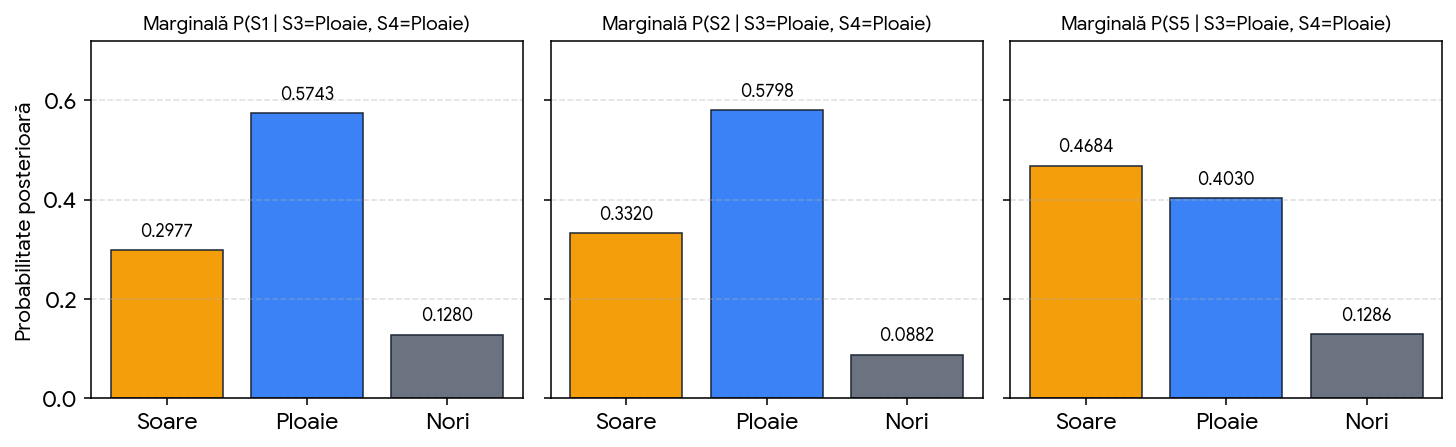

In [3]:
evidence = {"S3": "Ploaie", "S4": "Ploaie"}
unobserved = ["S1", "S2", "S5"]

if USE_PYAGRUM:
    ie = gum.ShaferShenoyMRFInference(mrf)
    ie.setEvidence(evidence)
    ie.makeInference()
    marginals = {}
    for st in unobserved:
        pot = ie.posterior(st)
        marginals[st] = np.array([pot[{st: s_name}] for s_name in states])
    joint_pot = ie.jointPosterior(set(unobserved))
    best_joint_prob = -1.0
    best_joint_cfg = None
    for s1 in states:
        for s2 in states:
            for s5 in states:
                p_val = float(joint_pot[{"S1": s1, "S2": s2, "S5": s5}])
                if p_val > best_joint_prob:
                    best_joint_prob = p_val
                    best_joint_cfg = (s1, s2, s5)
else:
    ev_idx = {stations.index(k): states.index(v) for k, v in evidence.items()}
    mask = np.array([all(cfg[k] == val for k, val in ev_idx.items()) for cfg in all_configs])
    sub_configs = [all_configs[i] for i in range(len(all_configs)) if mask[i]]
    sub_probs = joint_probs[mask] / np.sum(joint_probs[mask])
    marginals = {}
    for st in unobserved:
        u = stations.index(st)
        marginals[st] = np.array([np.sum(sub_probs[[j for j, c in enumerate(sub_configs) if c[u] == s]]) for s in range(3)])
    best_idx = int(np.argmax(sub_probs))
    best_joint_prob = float(sub_probs[best_idx])
    best_joint_cfg = tuple(states[sub_configs[best_idx][stations.index(st)]] for st in unobserved)

print("=== d) Distribuții marginale posterioare P(S_k | S3=Ploaie, S4=Ploaie) ===")
marginal_map_tuple = []
for st in unobserved:
    mp = marginals[st]
    best_st = states[int(np.argmax(mp))]
    marginal_map_tuple.append(best_st)
    print(f"  {st}: Soare={mp[0]:.4f}, Ploaie={mp[1]:.4f}, Nori={mp[2]:.4f}  -->  MAP marginal: {best_st}")

print("\n=== e) Configurația comună MAP vs. maximele marginale ===")
print(f"  Vectorul maximelor marginale (S1, S2, S5): {tuple(marginal_map_tuple)}")
print(f"  Configurația comună MAP      (S1, S2, S5): {best_joint_cfg}  (P = {best_joint_prob:.4f})")
print(f"  Coincid cele două rezultate? {tuple(marginal_map_tuple) == best_joint_cfg}")

# Grafic distribuții marginale
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3), sharey=True)
colors_bar = ["#F59E0B", "#3B82F6", "#6B7280"]
for ax_i, st in enumerate(unobserved):
    mp = marginals[st]
    bars = axes[ax_i].bar(states, mp, color=colors_bar, edgecolor="#1F2937", linewidth=0.8)
    axes[ax_i].set_title(f"Marginală P({st} | S3=Ploaie, S4=Ploaie)", fontsize=10, fontweight="bold")
    axes[ax_i].set_ylim(0, 0.72)
    axes[ax_i].grid(axis="y", linestyle="--", alpha=0.4)
    for b, val in zip(bars, mp):
        axes[ax_i].text(b.get_x() + b.get_width()/2, val + 0.02, f"{val:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Probabilitate posterioară")
plt.tight_layout()
plt.show()

**Concluzie Exercițiul 2e — Coincid întotdeauna MAP-ul comun și maximele marginale?**

**Nu, nu coincid întotdeauna!** După cum demonstrează exemplul de mai sus:
- **Maximele marginale separate** dau `(Ploaie, Ploaie, Soare)`. De ce preferă $S_5$ starea `Soare` marginal? Deoarece probabilitatea marginală $P(S_5 \mid E_{\text{obs}}) = \sum_{s_1, s_2} P(S_1=s_1, S_2=s_2, S_5 \mid E_{\text{obs}})$ însumează peste *toate* stările posibile ale vecinului său $S_2$; în scenariile în care $S_2 = \text{Soare}$ (probabilitate $0.3320$), prior-ul mare $p_5(\text{Soare}) = 0.5$ combinat cu $\Psi_{\text{Soare}, \text{Soare}} = 0.7$ ridică probabilitatea marginală totală a lui `Soare` la $0.4684 > 0.4030$.
- **Configurația comună MAP** este `(Ploaie, Ploaie, Ploaie)` ($P = 0.2412$). Atunci când fixăm simultan $S_1 = \text{Ploaie}$ și $S_2 = \text{Ploaie}$, interacțiunea de pe muchia $(S_2, S_5)$ favorizează net $S_5 = \text{Ploaie}$ ($p_5(\text{Ploaie})\Psi_{\text{Ploaie},\text{Ploaie}} = 0.3 \times 0.6 = 0.18 > p_5(\text{Soare})\Psi_{\text{Ploaie},\text{Soare}} = 0.5 \times 0.2 = 0.10$), deci configurația global coerentă `(Ploaie, Ploaie, Ploaie)` are probabilitate comună mai mare decât `(Ploaie, Ploaie, Soare)` ($P = 0.1340$).

---
## Exercițiul 3. Restaurarea unei imagini binare cu un MRF

### a) & b) Construirea imaginii binare $5 \times 5$ și adăugarea zgomotului (~10%)
Construim o imagine binară $x \in \{0, 1\}^{5 \times 5}$ reprezentând un pătrat alb ($1$) de dimensiune $3 \times 3$ centrat pe fond negru ($0$). Folosind o sămânță aleatoare fixă (`seed = 0`), inversăm $3$ pixeli din $25$ ($12\% \approx 10\%$) pentru a obține imaginea observată zgomotoasă $y$.

Matricea originală x:
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]

Matricea observată cu zgomot y (pixeli inversați la indicii liniari [15, 12, 19] ):
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 0 1 0]
 [1 1 1 1 1]
 [0 0 0 0 0]]
Număr pixeli diferiți între x și y: 3 / 25 (12%)


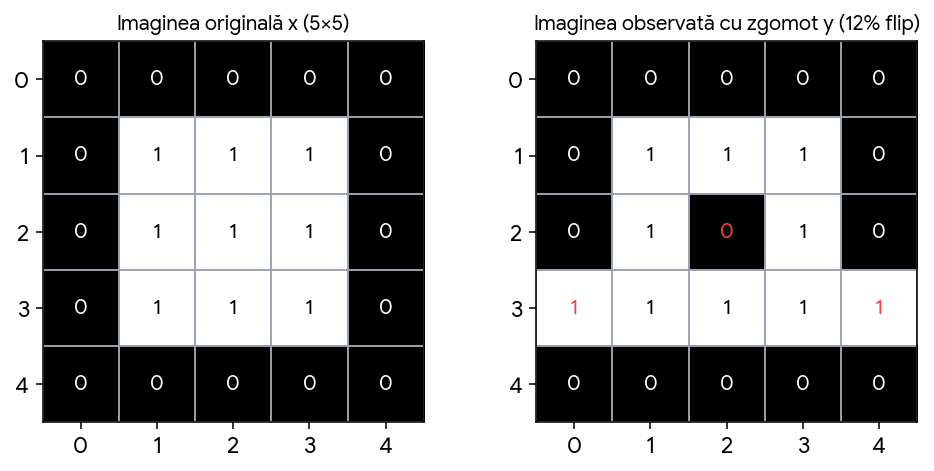

In [4]:
# a) Imaginea originală 5x5 (pătrat alb 3x3 pe fond negru)
orig = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
], dtype=int)

# b) Adăugarea zgomotului (~10%, 3 pixeli inversați din 25) cu seed fix
rng = np.random.default_rng(0)
flip_indices = rng.choice(25, size=3, replace=False)
y_noisy = orig.copy().ravel()
y_noisy[flip_indices] ^= 1
y_noisy = y_noisy.reshape(5, 5)

print("Matricea originală x:")
print(orig)
print("\nMatricea observată cu zgomot y (pixeli inversați la indicii liniari", flip_indices.tolist(), "):")
print(y_noisy)
print(f"Număr pixeli diferiți între x și y: {np.sum(orig != y_noisy)} / 25 ({100 * np.mean(orig != y_noisy):.0f}%)")

# Afișarea alăturată a imaginilor x și y
fig, (ax_o, ax_n) = plt.subplots(1, 2, figsize=(7.2, 3.4))
for ax_cur, mat, title in [(ax_o, orig, "Imaginea originală x (5×5)"), (ax_n, y_noisy, "Imaginea observată cu zgomot y (12% flip)")]:
    ax_cur.imshow(mat, cmap="gray", vmin=0, vmax=1)
    ax_cur.set_xticks(range(5))
    ax_cur.set_yticks(range(5))
    ax_cur.set_xticks(np.arange(-0.5, 5, 1), minor=True)
    ax_cur.set_yticks(np.arange(-0.5, 5, 1), minor=True)
    ax_cur.grid(which="minor", color="#9CA3AF", linestyle="-", linewidth=1)
    ax_cur.tick_params(which="minor", bottom=False, left=False)
    for r in range(5):
        for c in range(5):
            txt_col = "black" if mat[r, c] == 1 else "white"
            if mat is y_noisy and mat[r, c] != orig[r, c]:
                txt_col = "#EF4444"
            ax_cur.text(c, r, str(mat[r, c]), ha="center", va="center", color=txt_col, fontweight="bold", fontsize=11)
    ax_cur.set_title(title, fontsize=10.5, fontweight="bold")
plt.tight_layout()
plt.show()

### c) Modelul MRF pe grila $5 \times 5$, funcția de energie și potențialele

Asociem fiecărui pixel $(r, c)$ o variabilă binară $x_i \in \{0, 1\}$ ($25$ noduri) conectată cu vecinii săi direcți (sus, jos, stânga, dreapta — $40$ muchii în 4-vecinătate).

**Funcția de energie:**
$$E(x; y) = \underbrace{\lambda \sum_{i=1}^{25} (x_i - y_i)^2}_{\text{Termenul de fidelitate (date)}} + \underbrace{\sum_{(i, j) \in E} (x_i - x_j)^2}_{\text{Termenul de netezire (regularizare)}}, \qquad \lambda > 0.$$

- **Rolul termenului unar (de date / fidelitate):** $\lambda \sum_i (x_i - y_i)^2$ penalizează cu $\lambda$ fiecare pixel reconstruit $x_i$ care diferă de valoarea observată $y_i$. Cu cât $\lambda$ este mai mare, cu atât modelul este forțat să rămână fidel observațiilor zgomotoase.
- **Rolul termenului pereche (de regularizare / netezire):** $\sum_{(i, j) \in E} (x_i - x_j)^2$ adaugă o penalizare $+1$ pentru fiecare pereche de pixeli vecini cu culori diferite ($x_i \neq x_j$), încurajând regiunile omogene (netede) și eliminând pixelii izolați de zgomot.

**Legătura cu distribuția Gibbs / MRF:**
$$P(x \mid y) = \frac{1}{Z(y)} e^{-E(x; y)} = \frac{1}{Z(y)} \prod_{i=1}^{25} \phi_i(x_i) \prod_{(i, j) \in E} \phi_{ij}(x_i, x_j),$$
unde:
- **Potențialele unare:** $\phi_i(x_i) = e^{-\lambda (x_i - y_i)^2}$ (valoare $1$ dacă $x_i = y_i$, respectiv $e^{-\lambda}$ dacă $x_i \neq y_i$).
- **Potențialele pereche:** $\phi_{ij}(x_i, x_j) = e^{-(x_i - x_j)^2}$ (valoare $1$ dacă $x_i = x_j$, respectiv $e^{-1}$ dacă $x_i \neq x_j$).

Graful MRF pe grilă: |V| = 25 noduri, |E| = 40 muchii


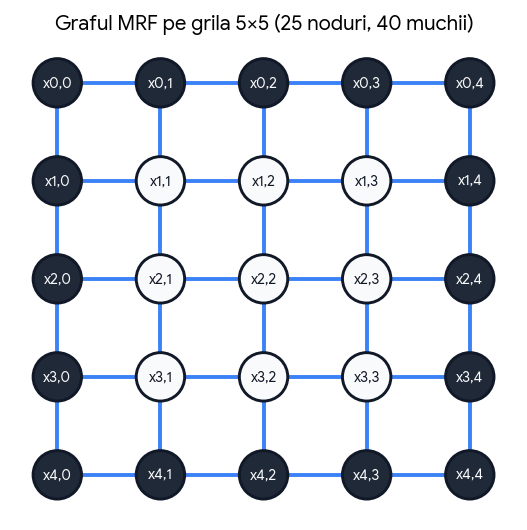

In [5]:
# Vizualizarea grafului MRF 5x5 (4-vecinătate)
G_grid = nx.grid_2d_graph(5, 5)
print(f"Graful MRF pe grilă: |V| = {G_grid.number_of_nodes()} noduri, |E| = {G_grid.number_of_edges()} muchii")

fig, ax_g = plt.subplots(figsize=(4.6, 4.4))
pos_grid = {(r, c): (c, 4 - r) for r, c in G_grid.nodes()}
node_colors_g = ["#F9FAFB" if orig[r, c] == 1 else "#1F2937" for r, c in G_grid.nodes()]
font_colors_g = ["#111827" if orig[r, c] == 1 else "#F9FAFB" for r, c in G_grid.nodes()]
nx.draw_networkx_edges(G_grid, pos_grid, ax=ax_g, width=2.0, edge_color="#3B82F6")
nx.draw_networkx_nodes(G_grid, pos_grid, ax=ax_g, node_size=620, node_color=node_colors_g, edgecolors="#111827", linewidths=1.5)
for (r, c), fc in zip(G_grid.nodes(), font_colors_g):
    ax_g.text(c, 4 - r, f"x{r},{c}", ha="center", va="center", color=fc, fontsize=7.5, fontweight="bold")
ax_g.set_title("Graful MRF pe grila 5×5 (25 noduri, 40 muchii)", fontsize=10.5, fontweight="bold")
ax_g.axis("off")
plt.show()

### d) & e) Construirea factorilor MRF, restaurarea prin ICM și analiza parametrului $\lambda \in \{0.3, 1.0, 3.0\}$

**Descrierea algoritmului ICM (Iterated Conditional Modes):**
Pentru a maximiza $P(x \mid y) \propto e^{-E(x; y)}$, este echivalent să minimizăm energia $E(x; y)$. ICM este un algoritm de **căutare locală (coordinate descent)** care procedează astfel:
1. Inițializează configurația curentă cu imaginea observată: $x^{(0)} = y$.
2. La fiecare iterație, parcurge secvențial toți pixelii $i = 1, \dots, 25$ și actualizează fiecare pixel $x_i$ cu valoarea din $\{0, 1\}$ care minimizează energia locală condiționată de vecinii săi curenți $N(i)$ (pătura Markov a lui $x_i$):
   $$x_i^{\text{nou}} = \arg\min_{v \in \{0, 1\}} \left[ \lambda (v - y_i)^2 + \sum_{j \in N(i)} (v - x_j)^2 \right].$$
3. Se oprește la convergență, atunci când o trecere completă peste grilă nu mai modifică niciun pixel.

> **Observație importantă:** Deoarece ICM actualizează câte un singur pixel la un moment dat, energia $E(x; y)$ scade monoton la fiecare pas, garantând convergența rapidă, dar **poate rămâne blocat într-un minim local** al energiei (nu garantează atingerea minimului global MAP).

Parametru λ    | Iterații ICM  | Energie E(x*; y)  | Pixeli greșiți vs. original
------------------------------------------------------------------------------
λ = 0.3        | 3             | 11.50             | 6 / 25 (24%)
λ = 1.0        | 2             | 15.00             | 0 / 25 (0%)
λ = 3.0        | 2             | 17.00             | 2 / 25 (8%)


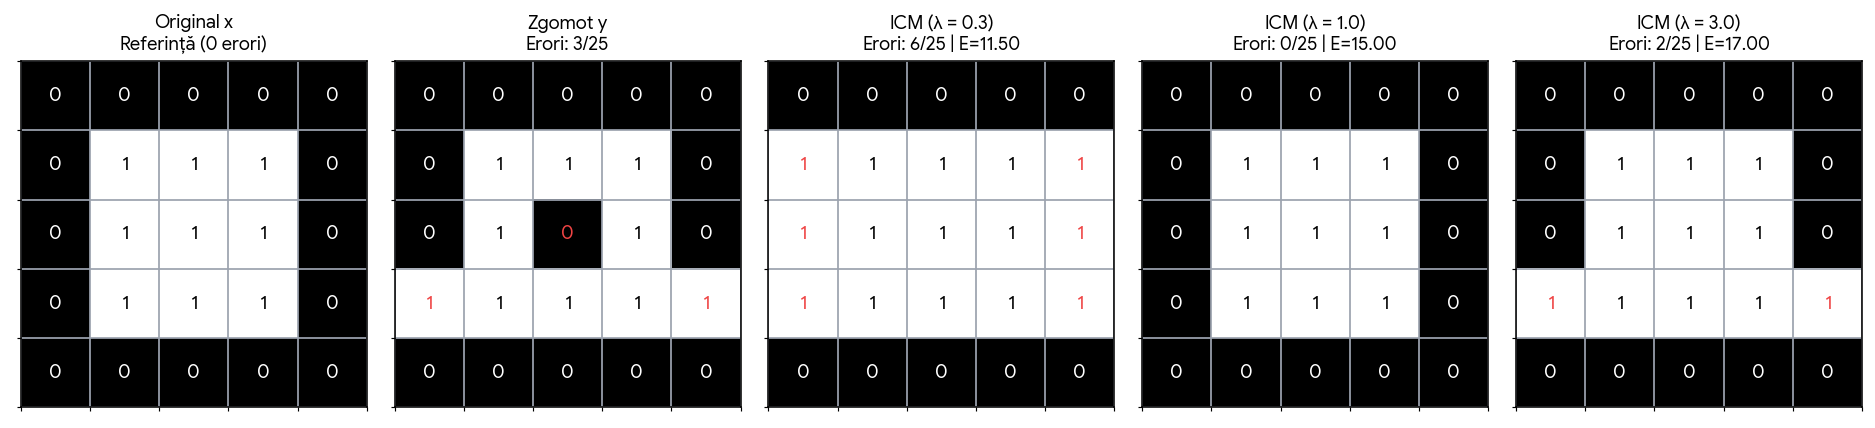

In [6]:
def build_image_mrf_pyagrum(y_mat, lam):
    """Construiește explicit factorii unari și pereche în pyAgrum pentru grila 5x5."""
    if not USE_PYAGRUM:
        return None
    mrf_img = MRFClass()
    for r in range(5):
        for c in range(5):
            mrf_img.add(gum.LabelizedVariable(f"x_{r}_{c}", f"Pixel ({r},{c})", ["0", "1"]))
    # Factori unari phi_i(x_i) = exp(-lambda * (x_i - y_i)^2)
    for r in range(5):
        for c in range(5):
            vname = f"x_{r}_{c}"
            phi_u = gum.Potential().add(mrf_img.variable(vname))
            for val in (0, 1):
                phi_u[{vname: str(val)}] = float(np.exp(-lam * ((val - y_mat[r, c]) ** 2)))
            mrf_img.addFactor(phi_u)
    # Factori pereche phi_ij(x_i, x_j) = exp(-(x_i - x_j)^2)
    for (r1, c1), (r2, c2) in G_grid.edges():
        v1, v2 = f"x_{r1}_{c1}", f"x_{r2}_{c2}"
        phi_p = gum.Potential().add(mrf_img.variable(v1)).add(mrf_img.variable(v2))
        for val1 in (0, 1):
            for val2 in (0, 1):
                phi_p[{v1: str(val1), v2: str(val2)}] = float(np.exp(-((val1 - val2) ** 2)))
        mrf_img.addFactor(phi_p)
    return mrf_img

def compute_energy(x, y, lam):
    unary = lam * np.sum((x - y) ** 2)
    horiz = np.sum((x[:, :-1] - x[:, 1:]) ** 2)
    vert = np.sum((x[:-1, :] - x[1:, :]) ** 2)
    return float(unary + horiz + vert)

def run_icm(y, lam, max_iter=50):
    x = y.copy()
    iters = 0
    for it in range(1, max_iter + 1):
        iters = it
        changed = False
        for r in range(5):
            for c in range(5):
                best_val = x[r, c]
                best_e = float("inf")
                for val in (0, 1):
                    e_loc = lam * ((val - y[r, c]) ** 2)
                    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                        nr, nc = r + dr, c + dc
                        if 0 <= nr < 5 and 0 <= nc < 5:
                            e_loc += (val - x[nr, nc]) ** 2
                    if e_loc < best_e:
                        best_e = e_loc
                        best_val = val
                if best_val != x[r, c]:
                    x[r, c] = best_val
                    changed = True
        if not changed:
            break
    return x, iters

lambdas = [0.3, 1.0, 3.0]
results = {}

print(f"{'Parametru λ':<14} | {'Iterații ICM':<13} | {'Energie E(x*; y)':<17} | {'Pixeli greșiți vs. original'}")
print("-" * 78)
for lam in lambdas:
    _ = build_image_mrf_pyagrum(y_noisy, lam)
    x_rec, n_it = run_icm(y_noisy, lam)
    err = int(np.sum(x_rec != orig))
    en = compute_energy(x_rec, y_noisy, lam)
    results[lam] = (x_rec, err, en)
    print(f"λ = {lam:<10.1f} | {n_it:<13d} | {en:<17.2f} | {err} / 25 ({100*err/25:.0f}%)")

# Vizualizarea comparativă a tuturor imaginilor
fig, axes = plt.subplots(1, 5, figsize=(13.5, 3.1))
panels = [
    ("Original x", orig, 0, compute_energy(orig, y_noisy, 1.0)),
    ("Zgomot y", y_noisy, int(np.sum(y_noisy != orig)), compute_energy(y_noisy, y_noisy, 1.0))
] + [(f"ICM (λ = {lam})", results[lam][0], results[lam][1], results[lam][2]) for lam in lambdas]

for ax_p, (title, mat, err, en) in zip(axes, panels):
    ax_p.imshow(mat, cmap="gray", vmin=0, vmax=1)
    ax_p.set_xticks(np.arange(-0.5, 5, 1), minor=True)
    ax_p.set_yticks(np.arange(-0.5, 5, 1), minor=True)
    ax_p.grid(which="minor", color="#9CA3AF", linestyle="-", linewidth=0.9)
    ax_p.set_xticks([])
    ax_p.set_yticks([])
    for r in range(5):
        for c in range(5):
            col = "black" if mat[r, c] == 1 else "white"
            if mat[r, c] != orig[r, c]:
                col = "#EF4444"
            ax_p.text(c, r, str(mat[r, c]), ha="center", va="center", color=col, fontweight="bold", fontsize=10)
    subtitle = "Referință (0 erori)" if "Original" in title else f"Erori: {err}/25"
    if "ICM" in title:
        subtitle += f" | E={en:.2f}"
    ax_p.set_title(f"{title}\n{subtitle}", fontsize=9.5, fontweight="bold")

plt.tight_layout()
plt.show()

### Interpretarea efectului parametrului $\lambda$

| Parametru | Energie finală $E(x^*; y)$ | Pixeli greșiți față de original | Comportament observat |
| :--- | :---: | :---: | :--- |
| **$\lambda = 0.3$** | $11.50$ | **6 / 25 (24%)** | **Supranetezire (over-smoothing):** Penalizarea pentru abaterea de la $y_i$ ($0.3$) este mult mai mică decât penalizarea de frontieră între vecini ($1.0$). Astfel, algoritmul preferă să elimine granițele verticale dintre alb și negru, extinzând benzile albe până la marginile grilei și distorsionând forma pătratului. |
| **$\lambda = 1.0$** | $15.00$ | **0 / 25 (0%)** | **Echilibru optim:** Un pixel zgomotos izolat are cel puțin $3$ sau $4$ vecini de culoare opusă, astfel încât inversarea lui economisește cel puțin $3 - 1 = 2$ unități de energie pereche față de costul $\lambda = 1.0$ de date. Toți cei $3$ pixeli corupți sunt corectați, iar pătratul original este reconstruit perfect. |
| **$\lambda = 3.0$** | $17.00$ | **2 / 25 (8%)** | **Fidelitate excesivă față de observație (under-smoothing):** Schimbarea unui pixel față de observația $y_i$ costă $\lambda = 3.0$. Pixelul zgomotos din centrul pătratului $(2,2)$ este corectat (economie $4 > 3$), dar cei doi pixeli zgomotoși de pe margine $(3,0)$ și $(3,4)$ au doar câte $2$ vecini negri și $1$ alb (economie netă $2 - 1 = 1 < 3.0$), deci rămân blocați la valoarea zgomotoasă $1$. |